# RiMEA 16: Looped Ring Parameter Study

This notebook rebuilds the RiMEA 16 one-dimensional loop from scratch using the oval helper pattern from the JuPedSim `single-file` notebook. Agents are placed directly along the loop to avoid compaction from a dense spawn area, then routed through three repeating checkpoints.

We keep $v_0 = 1.2$ m/s fixed and compare three target density levels, `0.5`, `0.8`, and `1.5` 1/m, against the RiMEA 16 reference 10% and 90% percentile band stored in `scenario_files/rimea16_percentile_reference.csv`.

## Acceptance

RiMEA asks to show the influence of the parameters and sets no pass limit. The V&V test (`TestRiMEA161DFundamentalDiagram`) therefore sweeps the agent count from free flow to congestion (last section) and requires: single-file order kept (no overtaking); mean speed not increasing with agent count and falling by at least 0.5 m/s overall; at least 75% of the density-binned speeds (bins with at least 50 samples) inside the 10/90% band. Plain `v0` variants at 10 agents additionally check that a slower `v0` gives lower speeds and a faster `v0` lies above the 90th percentile.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 10:50 CEST


In [2]:
from contextlib import redirect_stdout
import io

import matplotlib.pyplot as plt
import pandas as pd
import pedpy

from scenario_builders.rimea16_loop import (
    build_loop_geometry,
    build_loop_scenario,
    compute_density_speed_curve,
    compute_density_speed_samples,
    compute_lap_counts,
    load_reference_band,
    summarize_reference_fit,
)
from jupedsim_scenarios import run_sweep_from_factory

In [3]:
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "#fafafa",
        "axes.edgecolor": "#444444",
        "axes.titleweight": "bold",
        "font.size": 11,
    }
)

DESIRED_SPEED = 1.2
PREVIEW_GEOMETRY = build_loop_geometry()
TRACK_LENGTH = PREVIEW_GEOMETRY.track_length
DENSITY_CASES = [
    {
        "label": "low density",
        "target_density_1pm": 0.5,
        "num_agents": max(2, round(TRACK_LENGTH * 0.5)),
        "color": "#4C72B0",
    },
    {
        "label": "medium density",
        "target_density_1pm": 0.8,
        "num_agents": max(2, round(TRACK_LENGTH * 0.8)),
        "color": "#55A868",
    },
    {
        "label": "high density",
        "target_density_1pm": 1.5,
        "num_agents": max(2, round(TRACK_LENGTH * 1.5)),
        "color": "#C44E52",
    },
]
PREVIEW_SCENARIO, _ = build_loop_scenario(
    label="rimea16-preview",
    desired_speed=DESIRED_SPEED,
    num_agents=DENSITY_CASES[-1]["num_agents"],
    spacing=TRACK_LENGTH / DENSITY_CASES[-1]["num_agents"],
)
REFERENCE = load_reference_band()

pd.DataFrame(DENSITY_CASES)

,label,target_density_1pm,num_agents,color
0,low density,0.5,13,#4C72B0
1,medium density,0.8,21,#55A868
2,high density,1.5,40,#C44E52


## Geometry Preview

The oval ring is built from an outer and inner boundary, while the agents start already distributed along the centerline.

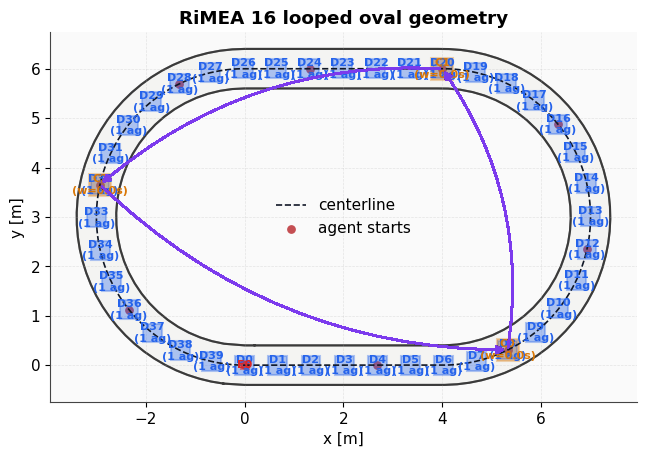

In [4]:
preview_geometry = PREVIEW_GEOMETRY
preview_fig, preview_ax = plt.subplots(figsize=(8, 4.8))
PREVIEW_SCENARIO.plot(ax=preview_ax)
x_center, y_center = preview_geometry.centerline.xy
preview_ax.plot(x_center, y_center, color="#111827", linestyle="--", linewidth=1.2, label="centerline")
positions = pd.DataFrame(preview_geometry.positions, columns=["x", "y"])
preview_ax.scatter(positions["x"], positions["y"], color="#C44E52", s=28, label="agent starts")
preview_ax.set_title("RiMEA 16 looped oval geometry")
preview_ax.legend(frameon=False)
plt.show()

## Parameter Sweep

The simulation cell is captured to suppress the shared runner's debug output.

## Measurement Method

The plotted x-axis is the **measured local density**, not just the three target density labels from the sweep.

- Density: for each frame, agent positions are projected onto the loop centerline. We compute the 1D Voronoi headway as `0.5 * distance_to_front + 0.5 * distance_to_back`, then convert it to density with `rho = 1 / headway`.
- Speed: positions are projected onto the same centerline and unwrapped over repeated laps. Speed is computed from the centerline displacement over a `10`-frame window, which is less noisy than frame-to-frame differences.
- Filtering: only samples after each agent has completed at least `3` laps are used for the speed-density analysis.
- Aggregation: the final curve uses density bins, but bins with fewer than `50` samples are dropped before plotting to avoid unstable outliers.

Because the local density varies over time and around the ring, one simulation run produces many density bins rather than a single point.

In [5]:
%%capture
# Factory-style sweep: each density case has its own geometry
# (spacing = TRACK_LENGTH / num_agents), so we can't mutate a base.
# build_loop_scenario returns (scenario, geometry); we pair them up
# in extras so the post-processing loop below can pull both back
# off each trial.
def _build(p):
    scenario, geometry = build_loop_scenario(
        label=f"rimea16-{p['label']}",
        desired_speed=DESIRED_SPEED,
        num_agents=p["num_agents"],
        spacing=TRACK_LENGTH / p["num_agents"],
        max_simulation_time=180.0,
    )
    return scenario, (scenario, geometry)


with redirect_stdout(io.StringIO()):
    sweep = run_sweep_from_factory(
        _build,
        trials=DENSITY_CASES,
        seeds=[42],
        workers=len(DENSITY_CASES),
    )

runs = {}
for trial in sweep.trials:
    params = trial.axis_values
    scenario, geometry = trial.extras
    result = trial.result
    traj_df = result.trajectory_dataframe()[["id", "frame", "x", "y"]].copy()
    samples = compute_density_speed_samples(
        trajectory_df=traj_df,
        frame_rate=result.frame_rate,
        centerline=geometry.centerline,
        track_length=geometry.track_length,
    )
    curve = compute_density_speed_curve(samples, min_samples=50)
    fit = summarize_reference_fit(curve, REFERENCE)
    lap_counts = compute_lap_counts(traj_df, geometry.centerline, geometry.track_length)
    traj = pedpy.TrajectoryData(traj_df, frame_rate=result.frame_rate)
    runs[params['label']] = {
        "params": params,
        "scenario": scenario,
        "geometry": geometry,
        "samples": samples,
        "curve": curve,
        "fit": fit,
        "lap_counts": lap_counts,
        "trajectory": traj,
        "first_frame": traj_df.loc[traj_df['frame'] == traj_df['frame'].min(), ['x', 'y']].copy(),
    }
sweep.cleanup()

## Trajectories

The three density cases share the same geometry and differ only in the number of agents on the loop. Hollow circle markers highlight the first frame of the agents.

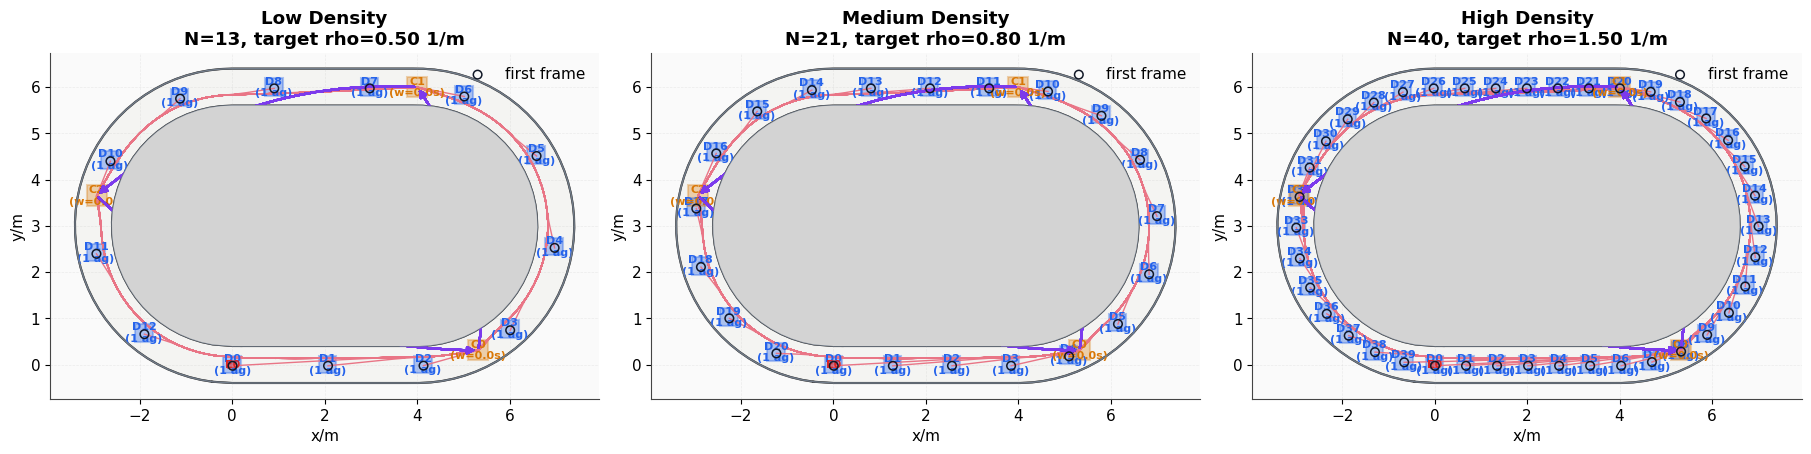

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
for ax, label in zip(axes, ["low density", "medium density", "high density"]):
    run = runs[label]
    run["scenario"].plot(ax=ax)
    pedpy.plot_trajectories(
        traj=run["trajectory"],
        walkable_area=pedpy.WalkableArea(run["scenario"].walkable_polygon),
        axes=ax,
        alpha=0.7,
        linewidth=0.8,
        color=run["params"]["color"],
    ).set_aspect("equal")
    ax.scatter(
        run["first_frame"]["x"],
        run["first_frame"]["y"],
        s=38,
        facecolors="none",
        edgecolors="#111827",
        linewidths=1.1,
        zorder=5,
        label="first frame",
    )
    ax.set_title(
        f"{label.title()}\n"
        f"N={run['params']['num_agents']}, target rho={run['params']['target_density_1pm']:.2f} 1/m"
    )
    ax.grid(alpha=0.2, linestyle="--")
    ax.legend(frameon=False, loc="upper right")
plt.show()

## Aggregated Speed-Density Curves vs Reference Percentiles

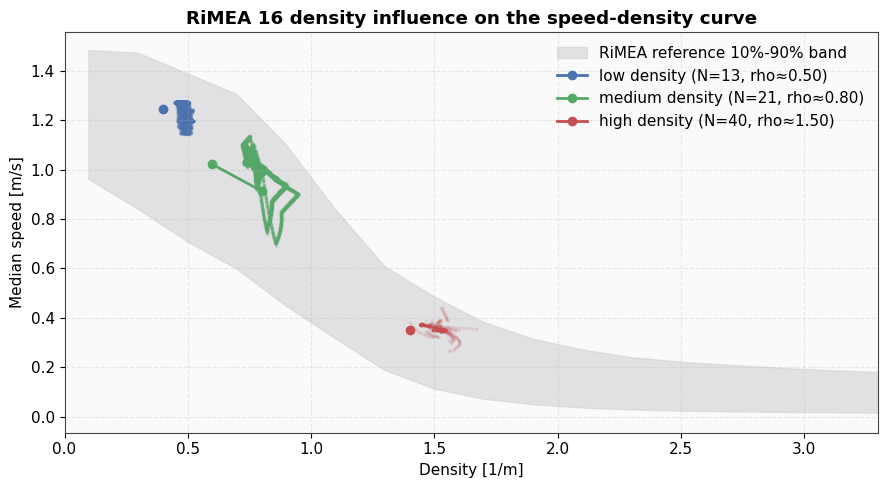

In [7]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.fill_between(
    REFERENCE["density_1pm"],
    REFERENCE["speed_p10_mps"],
    REFERENCE["speed_p90_mps"],
    color="#d4d4d8",
    alpha=0.65,
    label="RiMEA reference 10%-90% band",
)
for params in DENSITY_CASES:
    samples = runs[params['label']]["samples"]
    ax.scatter(
        samples["density_1pm"],
        samples["speed_mps"],
        s=6,
        alpha=0.06,
        color=params["color"],
        linewidths=0,
    )
    curve = runs[params['label']]["curve"]
    ax.plot(
        curve["density_1pm"],
        curve["speed_mps"],
        marker="o",
        linewidth=2,
        color=params["color"],
        label=(
            f"{params['label']} "
            f"(N={params['num_agents']}, rho≈{params['target_density_1pm']:.2f})"
        ),
    )
ax.set_title("RiMEA 16 density influence on the speed-density curve")
ax.set_xlabel("Density [1/m]")
ax.set_ylabel("Median speed [m/s]")
ax.set_xlim(0,3.3)
ax.grid(alpha=0.25, linestyle="--")
ax.legend(frameon=False)
plt.show()

In [8]:
summary_rows = []
for params in DENSITY_CASES:
    fit = runs[params['label']]["fit"]
    summary_rows.append(
        {
            "variant": params["label"],
            "v0 [m/s]": DESIRED_SPEED,
            "target density [1/m]": round(float(params["target_density_1pm"]), 3),
            "agents": params["num_agents"],
            "agents >= 3 laps": int((runs[params['label']]["lap_counts"]["completed_laps"] >= 3).sum()),
            "min laps": int(runs[params['label']]["lap_counts"]["completed_laps"].min()),
            "mean speed [m/s]": round(float(fit["speed_mps"].mean()), 3),
            "curve bins kept": int(len(runs[params['label']]["curve"])),
            "inside band": round(float(fit["inside_band"].mean()), 3),
            "below p10": round(float(fit["below_p10"].mean()), 3),
            "above p90": round(float(fit["above_p90"].mean()), 3),
        }
    )
pd.DataFrame(summary_rows)

,variant,v0 [m/s],target density [1/m],agents,agents >= 3 laps,min laps,mean speed [m/s],curve bins kept,inside band,below p10,above p90
0,low density,1.2,0.5,13,13,8,1.246,1,1.0,0.0,0.0
1,medium density,1.2,0.8,21,21,6,0.967,2,1.0,0.0,0.0
2,high density,1.2,1.5,40,17,2,0.350,1,1.0,0.0,0.0


## Density Sweep: Free Flow to Congestion

The ring is loaded with 5, 10, 20, 30, 40 and 45 agents (about 0.2 to 1.7 1/m) at $v_0 = 1.2$ m/s. The first lap is treated as warm-up. Samples are coloured by agent count. The overtaking check counts sampled frames whose cyclic agent order differs from the first frame; the lane is 0.8 m wide and agents are 0.3 m in diameter, so passing is geometrically possible although RiMEA asks for single-file motion.

In [9]:
%%capture
from scenario_builders.rimea16_loop import count_order_changes

SWEEP_AGENTS = [5, 10, 20, 30, 40, 45]
SWEEP_CASES = [{"label": f"N={n}", "num_agents": n} for n in SWEEP_AGENTS]


def _build_sweep(p):
    scenario, geometry = build_loop_scenario(
        label=f"rimea16-sweep-{p['num_agents']}",
        desired_speed=DESIRED_SPEED,
        num_agents=p["num_agents"],
        spacing=TRACK_LENGTH / p["num_agents"],
        max_simulation_time=180.0,
    )
    return scenario, geometry


with redirect_stdout(io.StringIO()):
    density_sweep = run_sweep_from_factory(
        _build_sweep, trials=SWEEP_CASES, seeds=[42], workers=3
    )

sweep_runs = {}
for trial in density_sweep.trials:
    n = trial.axis_values["num_agents"]
    geometry = trial.extras
    result = trial.result
    traj_df = result.trajectory_dataframe()[["id", "frame", "x", "y"]].copy()
    samples = compute_density_speed_samples(
        traj_df, result.frame_rate, geometry.centerline, geometry.track_length, min_laps=1
    )
    curve = compute_density_speed_curve(samples, min_samples=50)
    sweep_runs[n] = {
        "samples": samples,
        "fit": summarize_reference_fit(curve, REFERENCE),
        "sample_fit": summarize_reference_fit(samples, REFERENCE),
        "min_laps": int(compute_lap_counts(traj_df, geometry.centerline, geometry.track_length)["completed_laps"].min()),
        "order_changes": count_order_changes(traj_df, geometry.centerline),
    }
density_sweep.cleanup()

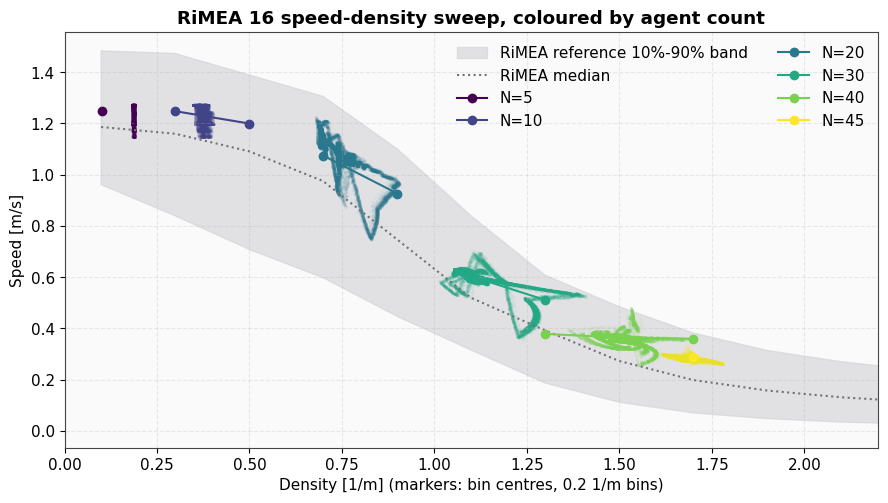

In [10]:
fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.fill_between(
    REFERENCE["density_1pm"], REFERENCE["speed_p10_mps"], REFERENCE["speed_p90_mps"],
    color="#d4d4d8", alpha=0.65, label="RiMEA reference 10%-90% band",
)
ax.plot(REFERENCE["density_1pm"], REFERENCE["speed_p50_mps"], color="#71717a", linestyle=":", label="RiMEA median")
cmap = plt.get_cmap("viridis")
for i, n in enumerate(SWEEP_AGENTS):
    s = sweep_runs[n]["samples"]
    color = cmap(i / (len(SWEEP_AGENTS) - 1))
    ax.scatter(s["density_1pm"], s["speed_mps"], s=5, alpha=0.05, color=color, linewidths=0)
    fit = sweep_runs[n]["fit"]
    ax.plot(fit["density_1pm"] + 0.1, fit["speed_mps"], marker="o", color=color, linewidth=1.5, label=f"N={n}")
ax.set_title("RiMEA 16 speed-density sweep, coloured by agent count")
ax.set_xlabel("Density [1/m] (markers: bin centres, 0.2 1/m bins)")
ax.set_ylabel("Speed [m/s]")
ax.set_xlim(0, 2.2)
ax.grid(alpha=0.25, linestyle="--")
ax.legend(frameon=False, ncol=2)
plt.show()

In [11]:
pd.DataFrame(
    [
        {
            "agents": n,
            "mean density [1/m]": round(float(r["samples"]["density_1pm"].mean()), 3),
            "mean speed [m/s]": round(float(r["samples"]["speed_mps"].mean()), 3),
            "min laps": r["min_laps"],
            "bins kept": len(r["fit"]),
            "bins inside band": round(float(r["fit"]["inside_band"].mean()), 3),
            "samples inside band": round(float(r["sample_fit"]["inside_band"].mean()), 3),
            "order changes (overtaking)": r["order_changes"],
        }
        for n, r in sweep_runs.items()
    ]
)

,agents,mean density [1/m],mean speed [m/s],min laps,bins kept,bins inside band,samples inside band,order changes (overtaking)
0,5,0.186,1.236,8,1,1.0,1.000,0
1,10,0.373,1.236,8,2,1.0,1.000,0
2,20,0.747,1.068,7,2,1.0,1.000,0
3,30,1.122,0.590,3,2,1.0,1.000,0
4,40,1.493,0.361,2,3,1.0,0.999,0
5,45,1.681,0.285,1,1,1.0,1.000,0
